# Spec-S5: z mag (AB) reaching $\sigma_{\rm RV}$ vs exposure time per tile

Depth at which Spec-S5 reaches $\sigma_{\rm RV}$ = 10 and 1 km/s as a function of exposure time per tile, with the equivalent single-pass survey area on the top axis.

**Assumptions**:
- ETC: `spec5.instrument.stellar_etc.compute_snr` (from `spec-s5-instrument/`), 107 µm fiber, flat-$f_\nu$ source
- Sub-exposures: $n_{\rm exp} = \lceil t/1200\,{\rm s} \rceil$ (causes minor features)
- $\sigma_{\rm RV}$ comes from the package's DESI-calibrated relation using the median z-arm (7470–9800 Å) SNR, with a 0.6 km/s systematic floor added in quadrature
- Survey area = (6 yr × 2 telescopes × 100 hr/yr of effective bright time) / $t_{\rm tile}$ × 2.2 deg² per pointing. This is a single pass with no overlap or overheads.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Note: this is a hack to allow importing from the spec-s5-instrument repo without installing it
sys.path.insert(0, str(Path.cwd() / "spec-s5-instrument"))
from spec5.instrument.stellar_etc import compute_snr

%matplotlib inline

## Parameters

In [2]:
# Survey time budget
YEARS, NTEL, HRS_PER_YR = 6, 2, 100
TOTAL_S = YEARS * NTEL * HRS_PER_YR * 3600.0   # effective seconds
FOV = 2.2                                      # deg^2 per pointing
NPOINT_FULL = 11500                            # pointings for ~25.3k deg^2

# ETC / RV
FIBER = 107          # um
VRAD_SYS = 0.6       # km/s systematic floor
SUBEXP = 1200        # s, max single sub-exposure
RV_LINES = [(10.0, "#08306b"), (1.0, "#d95f02")]   # (sigma_RV target in km/s, color)

# Plot range / marked exposure times
TMIN_PLOT, TMAX = 180, 10800
t_min = TOTAL_S / NPOINT_FULL                  # 375.65 s
MARK_T = [180, t_min, 900, 1800, 3600, 5400, 7200, 10800]

SAVE = True
OUTDIR = Path.cwd()

## Functions

In [3]:
def area(t):
    """Single-pass survey area (deg^2) for exposure time per tile t (s)."""
    return TOTAL_S / np.asarray(t, float) * FOV


def t_from_area(a):
    with np.errstate(divide="ignore"):
        return TOTAL_S * FOV / np.asarray(a, float)


def rv_precision(mags, texp):
    nexp = int(np.ceil(texp / SUBEXP))
    res = compute_snr(mags, nexp=nexp, texp=texp, fiber_diameter=FIBER)
    return np.hypot(res["VRAD_ERR"], VRAD_SYS)


def zmag_at_rv(texp, target, mags=np.linspace(12, 25, 1301)):
    """z mag (AB) where sigma_RV = target. sigma_RV increases monotonically with mag."""
    return np.interp(target, rv_precision(mags, texp), mags)

## Compute curves

In [ ]:
t2 = np.geomspace(TMIN_PLOT, TMAX, 300)
curves = {rv: np.array([zmag_at_rv(tt, rv) for tt in t2]) for rv, _ in RV_LINES}

print(f"t for {NPOINT_FULL} pointings ({area(t_min):,.0f} deg^2): {t_min:.1f} s\n")
print(f"{'texp':>6} {'nexp':>4} {'area':>8} " + " ".join(f"{'z@'+format(rv,'g')+'km/s':>10}" for rv, _ in RV_LINES))
for tm in MARK_T:
    print(f"{tm:6.0f} {int(np.ceil(tm/SUBEXP)):4d} {area(tm):8,.0f} "
          + " ".join(f"{zmag_at_rv(tm, rv):10.2f}" for rv, _ in RV_LINES))

## Figure

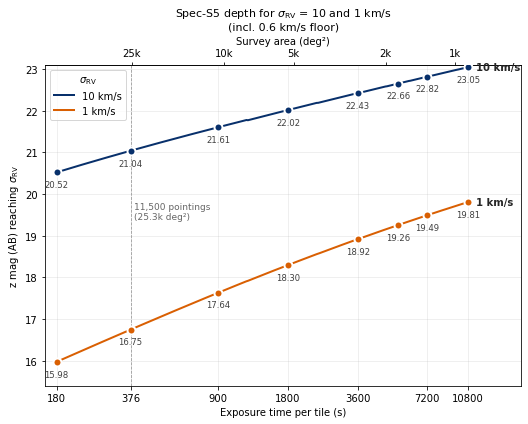

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for rv, col in RV_LINES:
    ax.plot(t2, curves[rv], color=col, lw=2, label=f"{rv:g} km/s")
    ax.text(TMAX * 1.08, curves[rv][-1], f"{rv:g} km/s", color="0.15",
            fontsize=10, fontweight="bold", va="center")
    for tm in MARK_T:
        zm = zmag_at_rv(tm, rv)
        ax.plot(tm, zm, "o", ms=8, color=col, mec="white", mew=2, zorder=3)
        ax.annotate(f"{zm:.2f}", (tm, zm), xytext=(0, -15), ha="center",
                    textcoords="offset points", fontsize=8.5, color="0.25")
ax.axvline(t_min, color="0.6", ls="--", lw=0.8)
ax.text(t_min * 1.03, 19.4, f"{NPOINT_FULL:,} pointings\n({area(t_min)/1e3:.1f}k deg²)",
        fontsize=9, color="0.4")
ax.set_xscale("log")
ax.set_xticks([180, 376, 900, 1800, 3600, 7200, 10800])
ax.set_xticklabels(["180", "376", "900", "1800", "3600", "7200", "10800"])
ax.minorticks_off()
ax.set_xlabel("Exposure time per tile (s)")
ax.set_ylabel(r"z mag (AB) reaching $\sigma_{\rm RV}$")
ax.set_title(r"Spec-S5 depth for $\sigma_{\rm RV}$ = "
             + " and ".join(f"{rv:g}" for rv, _ in RV_LINES) + " km/s"
             + "\n" + f"(incl. {VRAD_SYS} km/s floor)", fontsize=11)
ax.legend(loc="upper left", title=r"$\sigma_{\rm RV}$")
ax.grid(alpha=0.25)
ax.set_xlim(TMIN_PLOT * 0.89, TMAX * 1.7)
ax.set_ylim(15.4, 23.1)

# Top axis: the same exposure time re-expressed as survey area
top = ax.secondary_xaxis("top", functions=(area, t_from_area))
top.set_xlabel("Survey area (deg²)")
top.set_xticks([25000, 10000, 5000, 2000, 1000])
top.set_xticklabels(["25k", "10k", "5k", "2k", "1k"])
top.minorticks_off()
fig.tight_layout()
